# Nile Tilapia (*Oreochromis niloticus*) against Look-alike Fishes: Image Classifier
**Which of 6 species is in the photo? Target: Oreochromis niloticus. Compared against 5 look-alike / co-occurring fishes.**

Pipeline: harvest verified images (GBIF + iNaturalist, **max 200 per species**) -> clean and de-duplicate -> leakage-free split ->
custom-CNN baseline vs transfer learning (ResNet50, MobileNetV2) -> calibration -> honest evaluation -> export to ONNX for the browser (GitHub Pages).

**Runtime > Change runtime type > T4 GPU**, then *Run all*. Roughly 30-60 min.

Key safeguards kept from the previous version: perceptual-hash de-duplication, per-photographer cap, group-aware split (no photographer in both train and test),
class-balanced sampling, macro-F1, bootstrap confidence intervals, temperature calibration, Grad-CAM, licence filtering and `ATTRIBUTION.csv`.

## 1. Setup

In [ ]:
!pip -q install timm onnx onnxruntime imagehash

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 39.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 27.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 19.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 7.36.2 which is incompatible.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 7.36.2 which is incompatible.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.


In [ ]:
import os, io, re, json, time, random, hashlib, datetime, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import imagehash
from tqdm.auto import tqdm
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

import torch, torch.nn as nn, torch.nn.functional as F
import torchvision.transforms as T
import timm
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

warnings.filterwarnings("ignore")
SEED = 42
def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "| torch", torch.__version__, "| timm", timm.__version__)
if DEVICE == "cpu":
    print("WARNING: no GPU. Training will be slow. Runtime > Change runtime type > T4 GPU")

Device: cpu | torch 2.11.0+cpu | timm 1.0.29


## 2. Configuration

In [ ]:
ROOT = Path("/content/tilapia"); IMG_DIR = ROOT / "images"; OUT_DIR = ROOT / "export"
for p in (IMG_DIR, OUT_DIR): p.mkdir(parents=True, exist_ok=True)

# short key -> scientific name. The first entry is the TARGET species.
SPECIES = {
    "niloticus":    "Oreochromis niloticus",       # TARGET
    "aureus":       "Oreochromis aureus",
    "melanotheron": "Sarotherodon melanotheron",
    "zillii":       "Coptodon zillii",
    "gariepinus":   "Clarias gariepinus",
    "carpio":       "Cyprinus carpio",
}
TARGET = "niloticus"

# False -> 10 classes (one per species). True -> 2 classes: niloticus vs other_fish (all 9 others pooled).
GROUP_OTHERS = False
CLASSES = list(SPECIES) if not GROUP_OTHERS else [TARGET, "other_fish"]
label_of = lambda key: key if not GROUP_OTHERS else (TARGET if key == TARGET else "other_fish")

MAX_PER_SPECIES  = 200    # HARD CAP on images kept per species (applied after cleaning)
HARVEST_FACTOR   = 1.6    # ask for extra candidates, because some downloads fail / are duplicates
MAX_PER_OBSERVER = 15     # stops one prolific photographer dominating a class
MIN_SIDE         = 160    # drop tiny images
NEARDUP_HAMMING  = 6      # perceptual-hash distance (<=) treated as near-duplicate
ALLOWED_LICENSES = {"cc0", "cc-by", "cc-by-nc", "cc-by-sa", "cc-by-nc-sa"}   # no "nd" (derivatives needed)

IMG_SIZE = 224
BATCH, EPOCHS_HEAD, EPOCHS_FT = 32, 3, 15
INAT_DATASET_KEY = "50c9509d-22c7-4a22-a47d-8c48425ef4a7"   # iNaturalist inside GBIF (skipped to avoid double counting)
HEADERS = {"User-Agent": "tilapia-capstone/1.0 (student research project)"}

## 3. Harvest metadata from GBIF and iNaturalist
Only **human observations with photos** are used. Preserved museum specimens (formalin/ethanol) look very different from
fresh fish and would teach the wrong visual cues. iNaturalist records are pulled directly (research grade = community-verified);
the iNaturalist dataset is skipped inside GBIF so images are not counted twice.

In [ ]:
def http_get(url, params=None, retries=6):
    for i in range(retries):
        try:
            r = requests.get(url, params=params, headers=HEADERS, timeout=40)
            if r.status_code == 429:
                time.sleep(8 * (i + 1)); continue
            r.raise_for_status()
            return r.json()
        except requests.RequestException:
            time.sleep(2 * (i + 1))
    raise RuntimeError(f"Request kept failing: {url}")

def norm_license(s):
    if not s: return None
    s = str(s).lower().replace("_", "-")
    if "zero" in s or s == "cc0": return "cc0"
    m = re.search(r"licenses/(by(?:-nc)?(?:-sa)?(?:-nd)?)/", s)
    if m: return "cc-" + m.group(1)
    return s if s.startswith("cc-") else None

# ---------------- GBIF
def gbif_key(name):
    j = http_get("https://api.gbif.org/v1/species/match", {"name": name, "rank": "species"})
    if j.get("matchType") == "NONE" or "usageKey" not in j:
        return None, None
    return j.get("acceptedUsageKey") or j["usageKey"], j.get("scientificName")

def harvest_gbif(label, names, cap):
    sci = None
    key = None
    for n in names:
        key, sci = gbif_key(n)
        if key: break
    if not key:
        print(f"  GBIF: no match for {names}"); return []
    rows, offset = [], 0
    while len(rows) < cap and offset < 20000:
        j = http_get("https://api.gbif.org/v1/occurrence/search",
                     {"taxonKey": key, "mediaType": "StillImage", "basisOfRecord": "HUMAN_OBSERVATION",
                      "limit": 300, "offset": offset})
        for occ in j.get("results", []):
            if occ.get("datasetKey") == INAT_DATASET_KEY:
                continue
            observer = occ.get("recordedBy") or occ.get("datasetKey") or "unknown"
            for m in occ.get("media", [])[:1]:
                url = m.get("identifier")
                lic = norm_license(m.get("license") or occ.get("license"))
                if m.get("type") != "StillImage" or not url or lic not in ALLOWED_LICENSES:
                    continue
                rows.append(dict(label=label, source="gbif", species=sci, url=url, license=lic,
                                 observer=f"gbif:{observer}",
                                 attribution=m.get("rightsHolder") or m.get("creator") or observer,
                                 record=f"https://www.gbif.org/occurrence/{occ.get('key')}"))
        offset += 300
        if j.get("endOfRecords"): break
        time.sleep(0.3)
    print(f"  GBIF  {sci}: {len(rows)} usable images")
    return rows[:cap]

# ---------------- iNaturalist
def inat_taxon(names):
    for n in names:
        j = http_get("https://api.inaturalist.org/v1/taxa", {"q": n, "rank": "species", "per_page": 5})
        for t in j.get("results", []):
            if t["name"].lower() == n.lower():
                return t["id"], t["name"]
        time.sleep(1)
    return None, None

def harvest_inat(label, names, cap):
    sci = None
    tid, sci = inat_taxon(names)
    if not tid:
        print(f"  iNat: no taxon for {names}"); return []
    rows, page = [], 1
    while len(rows) < cap and page <= 50:
        j = http_get("https://api.inaturalist.org/v1/observations",
                     {"taxon_id": tid, "quality_grade": "research", "photos": "true",
                      "license": ",".join(sorted(ALLOWED_LICENSES)), "per_page": 200, "page": page})
        for o in j.get("results", []):
            for p in o.get("photos", [])[:1]:                   # first photo per observation only
                lic = norm_license(p.get("license_code"))
                if lic not in ALLOWED_LICENSES or not p.get("url"): continue
                uid = (o.get("user") or {}).get("id", "unknown")
                rows.append(dict(label=label, source="inaturalist", species=sci,
                                 url=p["url"].replace("square", "medium"), license=lic,
                                 observer=f"inat:{uid}", attribution=p.get("attribution", ""),
                                 record=o.get("uri", "")))
        if page * 200 >= j.get("total_results", 0): break
        page += 1; time.sleep(1.1)                             # iNaturalist asks for <= ~1 request/s
    print(f"  iNat  {sci}: {len(rows)} usable images")
    return rows[:cap]

all_rows = []
want = int(MAX_PER_SPECIES * HARVEST_FACTOR)
for key, sci_name in SPECIES.items():
    lab = label_of(key)
    print(f"[{key}] {sci_name}")
    # iNaturalist first (research grade = community-verified), then GBIF fills the gap
    rows = harvest_inat(lab, [sci_name], want)
    if len(rows) < want:
        rows += harvest_gbif(lab, [sci_name], want - len(rows))
    for r in rows: r["species_key"] = key
    all_rows += rows

meta = pd.DataFrame(all_rows).drop_duplicates("url").reset_index(drop=True)
meta["uid"] = [hashlib.md5(u.encode()).hexdigest()[:16] for u in meta.url]
print("\nCandidate images per species and source:")
print(meta.groupby(["species_key", "source"]).size().unstack(fill_value=0))

[niloticus] Oreochromis niloticus
  iNat  Oreochromis niloticus: 395 usable images
[aureus] Oreochromis aureus
  iNat  Oreochromis aureus: 389 usable images
[melanotheron] Sarotherodon melanotheron
  iNat  Sarotherodon melanotheron: 376 usable images
[zillii] Coptodon zillii
  iNat  Coptodon zillii: 393 usable images
[gariepinus] Clarias gariepinus
  iNat  Clarias gariepinus: 393 usable images
[carpio] Cyprinus carpio
  iNat  Cyprinus carpio: 393 usable images

Candidate images per species and source:
source        inaturalist
species_key              
aureus                320
carpio                320
gariepinus            320
melanotheron          320
niloticus             320
zillii                320


## 4. Download, validate, hash

In [ ]:
def fetch_one(row):
    path = IMG_DIR / row["label"] / f"{row['uid']}.jpg"
    try:
        if not path.exists():
            r = requests.get(row["url"], headers=HEADERS, timeout=40); r.raise_for_status()
            im = ImageOps.exif_transpose(Image.open(io.BytesIO(r.content))).convert("RGB")
            if min(im.size) < MIN_SIDE: return None
            im.thumbnail((512, 512))
            path.parent.mkdir(parents=True, exist_ok=True)
            im.save(path, quality=90)
        else:
            im = Image.open(path).convert("RGB")
        return {**row, "path": str(path), "phash": str(imagehash.phash(im)), "w": im.size[0], "h": im.size[1]}
    except Exception:
        return None

records = meta.to_dict("records")
with ThreadPoolExecutor(max_workers=8) as ex:
    results = list(tqdm(ex.map(fetch_one, records), total=len(records), desc="downloading"))
df = pd.DataFrame([r for r in results if r]).reset_index(drop=True)
print(f"Downloaded and valid: {len(df)} / {len(meta)}")

downloading:   0%|          | 0/1920 [00:00<?, ?it/s]

Downloaded and valid: 1911 / 1920


## 5. Clean: near-duplicates, label conflicts, observer cap
* Near-duplicates (same photo re-uploaded, or crops of it) are collapsed to one image.
* If near-duplicate images carry **different labels**, the identification is unreliable and all of them are dropped.
* At most `MAX_PER_OBSERVER` images per photographer.

In [ ]:
df_raw = df.copy()
H = np.array([int(h, 16) for h in df.phash], dtype=np.uint64)
POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
src, dst = [], []
for i in range(len(H) - 1):
    d = POP[(H[i + 1:] ^ H[i]).view(np.uint8).reshape(-1, 8)].sum(1)
    for j in np.nonzero(d <= NEARDUP_HAMMING)[0]:
        src.append(i); dst.append(i + 1 + j)
n = len(df)
graph = coo_matrix((np.ones(len(src)), (src, dst)), shape=(n, n))
_, comp = connected_components(graph, directed=False)
df["dup_cluster"] = comp

conflict = df.groupby("dup_cluster")["label"].nunique()
bad = set(conflict[conflict > 1].index)
before = len(df)
df = df[~df.dup_cluster.isin(bad)]
df = df.drop_duplicates("dup_cluster", keep="first")
print(f"Removed {before - len(df)} duplicates / conflicting images "
      f"({len(bad)} clusters had conflicting labels)")


df_precap = df.copy()
df = df.sample(frac=1, random_state=SEED)
df["_rank"] = df.groupby(["species_key", "observer"]).cumcount()
df = df[df._rank < MAX_PER_OBSERVER].drop(columns="_rank")
# hard cap: at most MAX_PER_SPECIES images per species
df = df.groupby("species_key", group_keys=False).head(MAX_PER_SPECIES).reset_index(drop=True)
df["y"] = df.label.map({c: i for i, c in enumerate(CLASSES)})
print(df.species_key.value_counts().to_string())
assert df.label.nunique() == len(CLASSES), "A class is empty - check the harvest step output above."
thin = df.species_key.value_counts()[lambda v: v < 40]
if len(thin): print("\nWARNING: very few images for", dict(thin), "- results for these species will be unreliable.")

Removed 3 duplicates / conflicting images (0 clusters had conflicting labels)
species_key
gariepinus      200
niloticus       200
carpio          200
zillii          200
aureus          200
melanotheron    200


## Explanation data analysis (EDA) : three charts to check class balance, how many photos each photographer contributed, and image sizes.

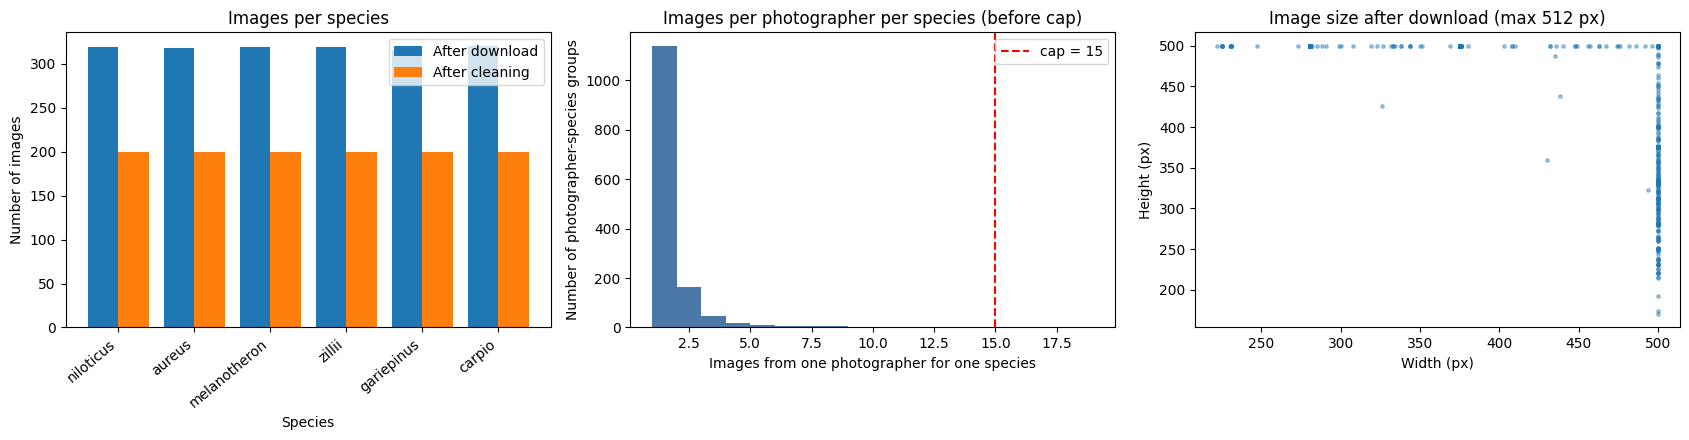

1396 photographer-species groups; 1 had more than 15 images; largest group: 18 images
1298 different photographers in total
Longer side: min 426, median 500, max 500


In [ ]:
# EDA.
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# 1) Class balance: after download vs after cleaning
order = list(SPECIES)
raw = df_raw.species_key.value_counts().reindex(order)
clean = df.species_key.value_counts().reindex(order)
x = np.arange(len(order))
ax[0].bar(x - 0.2, raw.values, 0.4, label="After download")
ax[0].bar(x + 0.2, clean.values, 0.4, label="After cleaning")
ax[0].set_xticks(x); ax[0].set_xticklabels(order, rotation=40, ha="right")
ax[0].set_xlabel("Species"); ax[0].set_ylabel("Number of images")
ax[0].set_title("Images per species"); ax[0].legend()

# 2) Photographer concentration, before the cap
# The cap is applied per species AND per photographer, so count the same way
per_obs = df_precap.groupby(["species_key", "observer"]).size().sort_values(ascending=False)
ax[1].hist(per_obs.values, bins=range(1, per_obs.max() + 2), color="#4c78a8")
ax[1].axvline(MAX_PER_OBSERVER, color="red", ls="--", label=f"cap = {MAX_PER_OBSERVER}")
ax[1].set_xlabel("Images from one photographer for one species")
ax[1].set_ylabel("Number of photographer-species groups")
ax[1].set_title("Images per photographer per species (before cap)"); ax[1].legend()

# 3) Image size (stored images are thumbnails, so the longer side is at most 512 px)
longer = np.maximum(df.w, df.h)
ax[2].scatter(df.w, df.h, s=6, alpha=0.4)
ax[2].set_xlabel("Width (px)"); ax[2].set_ylabel("Height (px)")
ax[2].set_title("Image size after download (max 512 px)")
plt.tight_layout(); plt.show()

over = (per_obs > MAX_PER_OBSERVER).sum()
print(f"{len(per_obs)} photographer-species groups; {over} had more than {MAX_PER_OBSERVER} images; "
      f"largest group: {per_obs.iloc[0]} images")
print(f"{df_precap.observer.nunique()} different photographers in total")
print(f"Longer side: min {longer.min()}, median {int(longer.median())}, max {longer.max()}")

### Visual spot-check (do this before training)
Open a few images per class. Remove anything that is not a clearly visible fish (maps, dead specimens in jars, labels, people).
Verified databases still contain mistakes, and bad images silently cap accuracy.

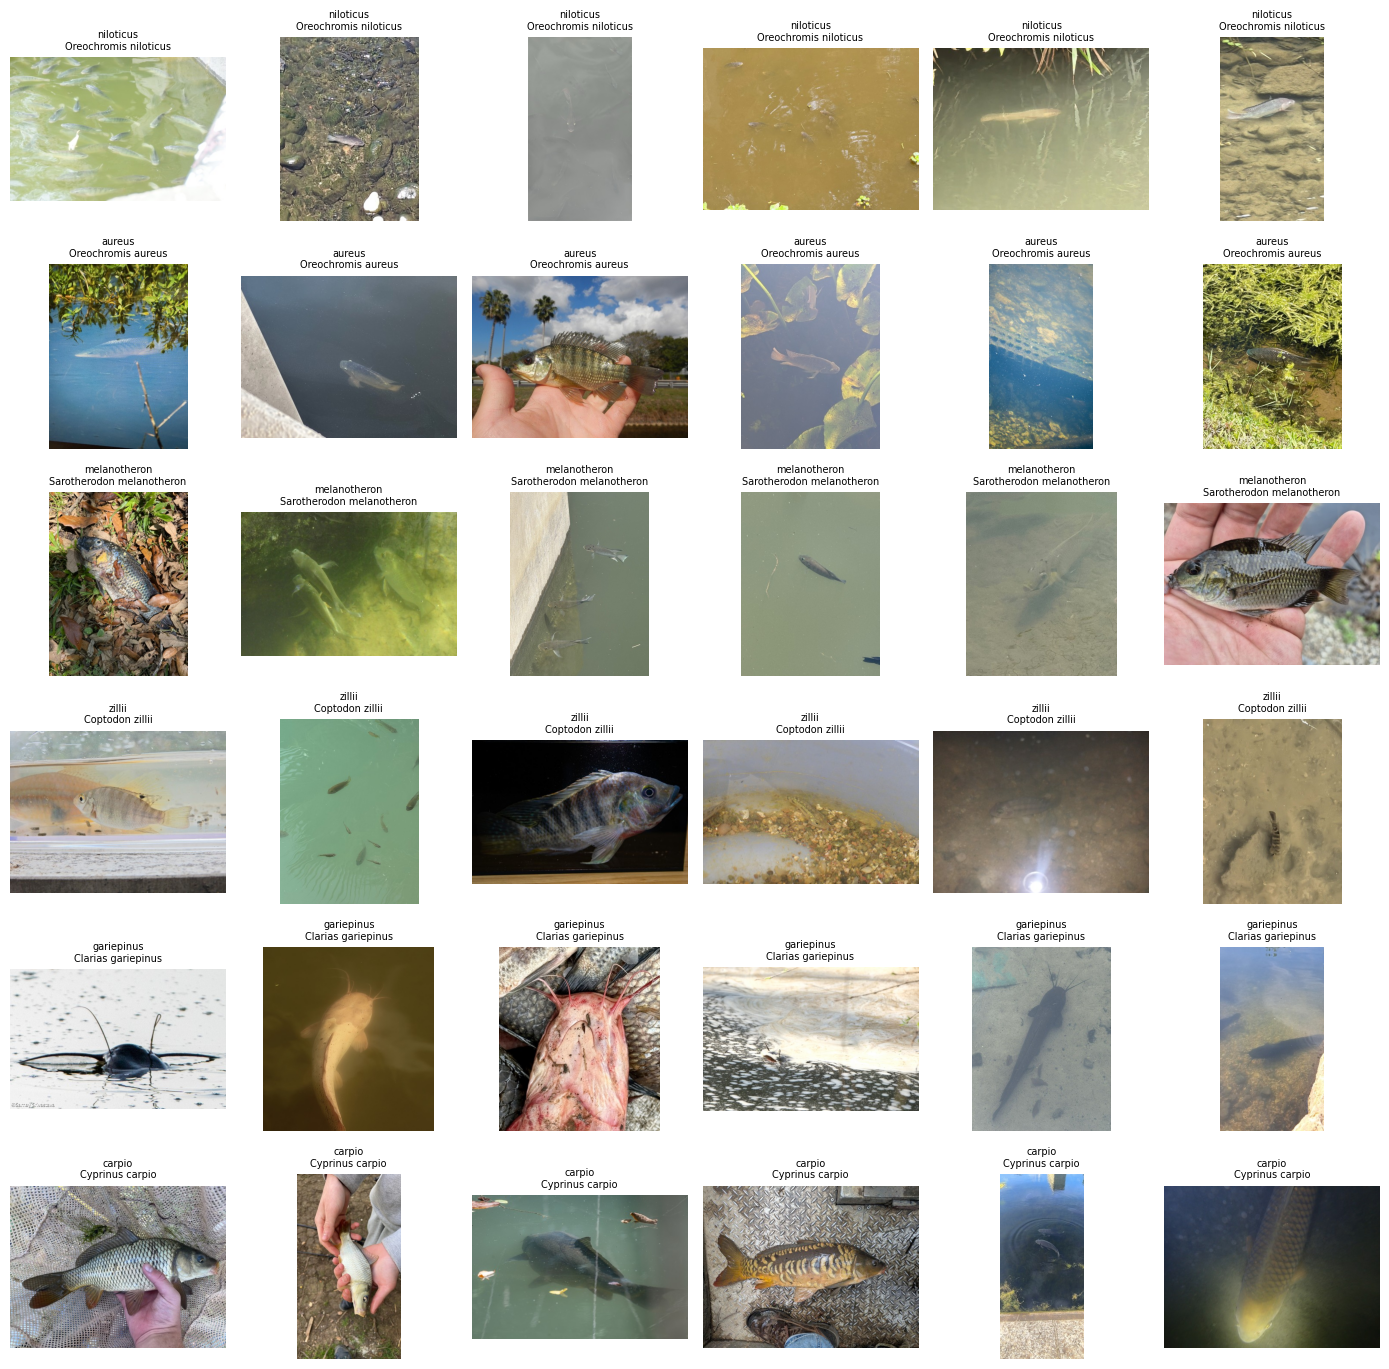

In [ ]:
n = len(CLASSES)
fig, axes = plt.subplots(n, 6, figsize=(14, 2.3 * n), squeeze=False)
for r, c in enumerate(CLASSES):
    sub = df[df.label == c]
    for ax in axes[r]: ax.axis("off")
    for ax, (_, row) in zip(axes[r], sub.sample(min(6, len(sub)), random_state=1).iterrows()):
        ax.imshow(Image.open(row.path)); ax.set_title(f"{c}\n{row.species}", fontsize=7)
plt.tight_layout(); plt.show()

## 6. Group-aware stratified split (train 80 / val 10 / test 10)
Every photographer's images stay in **one** split. This is the single most important fix for honest accuracy.

In [ ]:
sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
df["fold"] = -1
for k, (_, idx) in enumerate(sgkf.split(df, df.y, groups=df.observer)):
    df.loc[idx, "fold"] = k
df["split"] = np.where(df.fold == 0, "test", np.where(df.fold == 1, "val", "train"))

# leakage audit
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    shared = set(df[df.split == a].observer) & set(df[df.split == b].observer)
    assert not shared, f"observer leakage between {a} and {b}"
ct = pd.crosstab(df.split, df.label).reindex(columns=CLASSES, fill_value=0)
print(ct)
for c in CLASSES:
    for sp in ("val", "test"):
        if ct.loc[sp, c] < 3: print(f"WARNING: only {ct.loc[sp, c]} {c} images in {sp}: its score will be unreliable")

label  niloticus  aureus  melanotheron  zillii  gariepinus  carpio
split                                                             
test          17      29            31      14          32      14
train        159     153           154     167         151     163
val           24      18            15      19          17      23


## 7. Dataset and augmentation

In [ ]:
train_tf = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.5, 1.0), ratio=(0.75, 1.6)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(10),
    T.ColorJitter(0.3, 0.3, 0.3, 0.03),    # lighting varies a lot between markets, ponds and phones
    T.RandomApply([T.GaussianBlur(5, (0.1, 1.5))], p=0.2),   # phone motion blur
    T.ToTensor()])
eval_tf = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor()])   # whole fish, no crop

class FishDS(torch.utils.data.Dataset):
    def __init__(self, d, tf): self.p, self.y, self.tf = d.path.tolist(), d.y.tolist(), tf
    def __len__(self): return len(self.p)
    def __getitem__(self, i): return self.tf(Image.open(self.p[i]).convert("RGB")), self.y[i]

tr, va, te = (df[df.split == s] for s in ("train", "val", "test"))
cls_count = tr.y.value_counts().sort_index().values
sample_w = (1.0 / cls_count)[tr.y.values]                      # class-balanced sampling
sampler = torch.utils.data.WeightedRandomSampler(sample_w, num_samples=len(tr), replacement=True)
mk = lambda ds, **kw: torch.utils.data.DataLoader(ds, batch_size=BATCH, num_workers=2, pin_memory=True, **kw)
dl_tr = mk(FishDS(tr, train_tf), sampler=sampler)
dl_va = mk(FishDS(va, eval_tf), shuffle=False)
dl_te = mk(FishDS(te, eval_tf), shuffle=False)

### Augmentation preview
Tuned for fish: **no vertical flip** (fish are never upside down), mild rotation,
strong colour/brightness jitter (markets, ponds and phone cameras differ), and blur (motion).

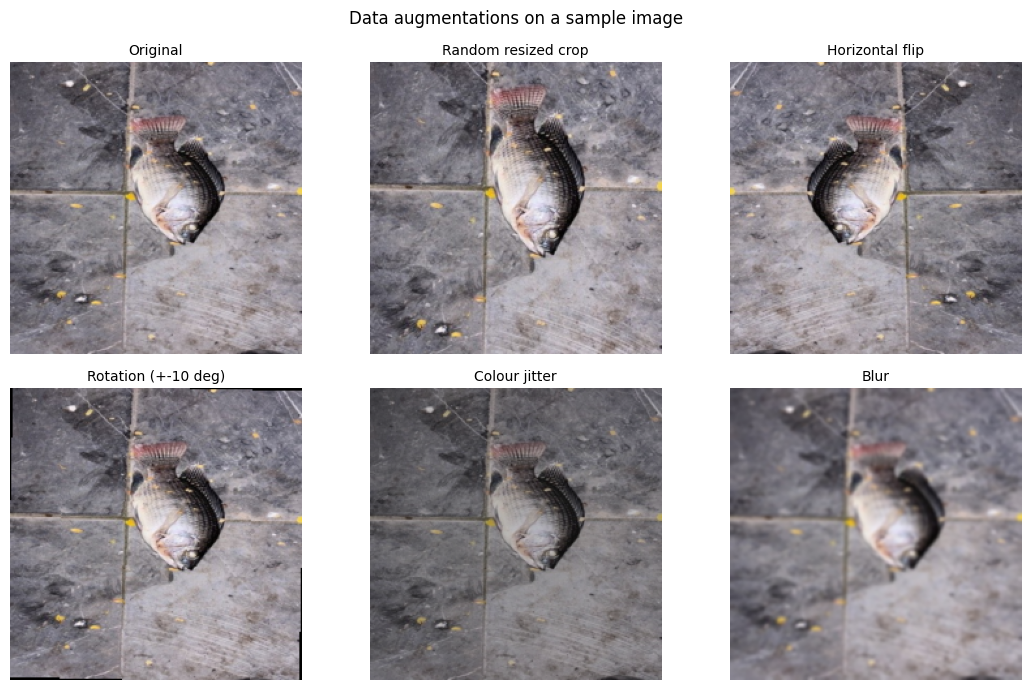

In [ ]:
base_img = Image.open(df[df.label == "niloticus"].iloc[0].path).convert("RGB")
R = T.Resize((IMG_SIZE, IMG_SIZE))
aug_demo = {
    "Original":            R,
    "Random resized crop": T.RandomResizedCrop(IMG_SIZE, scale=(0.5, 1.0), ratio=(0.75, 1.6)),
    "Horizontal flip":     T.Compose([R, T.RandomHorizontalFlip(p=1.0)]),
    "Rotation (+-10 deg)": T.Compose([R, T.RandomRotation(10)]),
    "Colour jitter":       T.Compose([R, T.ColorJitter(0.4, 0.4, 0.4, 0.05)]),
    "Blur":                T.Compose([R, T.GaussianBlur(5, (1.2, 1.5))]),
}
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for ax, (title, tf) in zip(axes.ravel(), aug_demo.items()):
    ax.imshow(tf(base_img)); ax.set_title(title, fontsize=10); ax.axis("off")
plt.suptitle("Data augmentations on a sample image"); plt.tight_layout(); plt.show()

## 8. Models: custom CNN baseline Against transfer learning
a CNN trained from scratch is the baseline and ImageNet-pretrained networks are compared against it.
All models see the **same splits, augmentation, sampler and training schedule**, and are selected on **validation macro-F1**
(never on the test set).

* `custom_cnn` - 4 conv blocks trained from scratch
* `resnet50` - accurate, but about 95 MB, too heavy for a free web page
* `mobilenetv2_100` - about 9 MB, fast in a browser; this is the model deployed to GitHub Pages

In [ ]:
MODELS = ["custom_cnn", "resnet50", "mobilenetv2_100"]
DEPLOY = "mobilenetv2_100"

class CustomCNN(nn.Module):
    def __init__(self, n):
        super().__init__()
        def block(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(256, 256),
                                  nn.ReLU(), nn.Dropout(0.5), nn.Linear(256, n))
    def forward(self, x): return self.head(self.features(x))
    def get_classifier(self): return self.head[-1]

class Net(nn.Module):
    def __init__(self, name, n_classes):
        super().__init__()
        self.b = CustomCNN(n_classes) if name == "custom_cnn" else \
                 timm.create_model(name, pretrained=True, num_classes=n_classes, drop_rate=0.3)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
    def forward(self, x):                       # x: RGB in [0,1]; normalisation lives inside the model
        return self.b((x - self.mean) / self.std)

crit = nn.CrossEntropyLoss(label_smoothing=0.1)

@torch.no_grad()
def predict_logits(model, dl):
    model.eval(); out, ys = [], []
    for x, y in dl:
        with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
            out.append(model(x.to(DEVICE)).float().cpu())
        ys.append(y)
    return torch.cat(out), torch.cat(ys)

def train_model(name):
    seed_everything()
    model = Net(name, len(CLASSES)).to(DEVICE)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")
    hist, best = [], {"f1": -1.0, "state": None}

    def fit(epochs, lr, tag):
        params = [p for p in model.parameters() if p.requires_grad]
        opt = torch.optim.AdamW(params, lr=lr, weight_decay=1e-2)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(dl_tr))
        for _ in range(epochs):
            model.train(); tot = 0.0
            for x, y in dl_tr:
                x, y = x.to(DEVICE), y.to(DEVICE)
                opt.zero_grad(set_to_none=True)
                with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
                    loss = crit(model(x), y)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
                tot += loss.item() * len(y)
            tl = tot / len(dl_tr.dataset)
            lg, ys = predict_logits(model, dl_va)
            f1 = f1_score(ys, lg.argmax(1), average="macro"); acc = accuracy_score(ys, lg.argmax(1))
            vl = F.cross_entropy(lg, ys).item()
            hist.append(dict(phase=tag, epoch=len(hist) + 1, train_loss=tl, val_loss=vl, val_acc=acc, val_f1=f1))
            flag = ""
            if f1 > best["f1"]:
                best["f1"], flag = f1, " *best*"
                best["state"] = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            print(f"[{name}/{tag}] epoch {len(hist):2d}  train_loss {tl:.3f}  val_loss {vl:.3f}  val_acc {acc:.3f}  val_macroF1 {f1:.3f}{flag}")

    if name == "custom_cnn":
        fit(EPOCHS_HEAD + EPOCHS_FT, 1e-3, "scratch")
    else:
        for p in model.b.parameters(): p.requires_grad = False          # phase 1: new head only
        for p in model.b.get_classifier().parameters(): p.requires_grad = True
        fit(EPOCHS_HEAD, 1e-3, "head")
        for p in model.parameters(): p.requires_grad = True              # phase 2: fine-tune everything
        fit(EPOCHS_FT, 3e-4, "finetune")
    model.load_state_dict(best["state"])
    return model.cpu(), pd.DataFrame(hist), best["f1"]

trained = {}
for name in MODELS:
    print(f"\n===== {name} =====")
    trained[name] = train_model(name)
    torch.cuda.empty_cache()


===== custom_cnn =====
[custom_cnn/scratch] epoch  1  train_loss 1.793  val_loss 1.781  val_acc 0.207  val_macroF1 0.138 *best*
[custom_cnn/scratch] epoch  2  train_loss 1.760  val_loss 1.781  val_acc 0.190  val_macroF1 0.164 *best*
[custom_cnn/scratch] epoch  3  train_loss 1.748  val_loss 1.831  val_acc 0.233  val_macroF1 0.194 *best*
[custom_cnn/scratch] epoch  4  train_loss 1.754  val_loss 1.782  val_acc 0.250  val_macroF1 0.186
[custom_cnn/scratch] epoch  5  train_loss 1.762  val_loss 1.827  val_acc 0.172  val_macroF1 0.150
[custom_cnn/scratch] epoch  6  train_loss 1.740  val_loss 1.836  val_acc 0.181  val_macroF1 0.136
[custom_cnn/scratch] epoch  7  train_loss 1.754  val_loss 1.810  val_acc 0.181  val_macroF1 0.166
[custom_cnn/scratch] epoch  8  train_loss 1.757  val_loss 1.781  val_acc 0.198  val_macroF1 0.182
[custom_cnn/scratch] epoch  9  train_loss 1.725  val_loss 1.789  val_acc 0.216  val_macroF1 0.207 *best*
[custom_cnn/scratch] epoch 10  train_loss 1.730  val_loss 1.817  v

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for name, (_, h, _) in trained.items():
    ax[0].plot(h.val_loss, label=name); ax[1].plot(h.val_f1, label=name)
ax[0].set_title("Validation loss"); ax[1].set_title("Validation macro-F1")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.show()

## 9. Model comparison
Test results are shown for every model for the report, but the deployed model was fixed in advance (`DEPLOY`) because of
size and speed; validation F1 is what drove checkpoint selection inside each run.

In [ ]:
rows = []
for name, (m, _, vf1) in trained.items():
    m.to(DEVICE)
    lg, ys = predict_logits(m, dl_te); p = lg.argmax(1).numpy()
    rows.append(dict(model=name, params_M=round(sum(q.numel() for q in m.parameters()) / 1e6, 2),
                     size_MB_fp32=round(sum(q.numel() for q in m.parameters()) * 4 / 1e6, 1),
                     val_macro_f1=round(vf1, 4), test_accuracy=round(accuracy_score(ys, p), 4),
                     test_macro_f1=round(f1_score(ys, p, average="macro"), 4),
                     test_weighted_f1=round(f1_score(ys, p, average="weighted"), 4)))
    m.cpu()
comparison = pd.DataFrame(rows)
display(comparison)

## 10. Calibration of the deployed model (temperature scaling on the validation set)
Raw softmax scores are usually over-confident. A single temperature `T` fitted on validation data makes the
percentage shown in the app mean something closer to reality.

In [ ]:
model = trained[DEPLOY][0].to(DEVICE)
val_logits, val_y = predict_logits(model, dl_va)
logT = torch.zeros(1, requires_grad=True)
opt = torch.optim.LBFGS([logT], lr=0.1, max_iter=100)
def closure():
    opt.zero_grad(); loss = F.cross_entropy(val_logits / logT.exp(), val_y); loss.backward(); return loss
opt.step(closure)
TEMP = float(logT.exp().item())
print(f"Fitted temperature T = {TEMP:.3f}  (T > 1 means the raw model was over-confident)")

def ece(probs, y, bins=10):
    conf, pred = probs.max(1); acc = (pred == y).float(); e = 0.0
    edges = torch.linspace(0, 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.float().mean() * (acc[m].mean() - conf[m].mean()).abs()
    return float(e)
print("Val ECE before:", round(ece(F.softmax(val_logits, 1), val_y), 4),
      "| after:", round(ece(F.softmax(val_logits / TEMP, 1), val_y), 4))

## 10b. Detailed test evaluation of the deployed model

In [ ]:
te_logits, te_y = predict_logits(model, dl_te)
te_prob = F.softmax(te_logits / TEMP, 1)
pred = te_prob.argmax(1).numpy(); y = te_y.numpy()
print(classification_report(y, pred, labels=list(range(len(CLASSES))), target_names=CLASSES, digits=3, zero_division=0))

N = len(CLASSES)
cm = confusion_matrix(y, pred, labels=list(range(N)))
fig, ax = plt.subplots(figsize=(max(4.8, 0.8 * N), max(4.2, 0.7 * N)))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(N)); ax.set_xticklabels(CLASSES, rotation=45, ha="right"); ax.set_yticks(range(N)); ax.set_yticklabels(CLASSES)
for i in range(N):
    for j in range(N): ax.text(j, i, cm[i, j], ha="center", va="center")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Test confusion matrix")
plt.tight_layout(); plt.savefig(OUT_DIR / "confusion_matrix.png", dpi=150); plt.show()

# bootstrap 95% confidence intervals (small test sets -> report uncertainty, not just a point value)
rng = np.random.default_rng(SEED); accs, f1s = [], []
for _ in range(1000):
    idx = rng.integers(0, len(y), len(y))
    accs.append(accuracy_score(y[idx], pred[idx])); f1s.append(f1_score(y[idx], pred[idx], average="macro"))
ci = lambda a: (float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5)))
metrics = dict(test_n=int(len(y)), accuracy=float(accuracy_score(y, pred)), accuracy_ci95=ci(accs),
               macro_f1=float(f1_score(y, pred, average="macro")), macro_f1_ci95=ci(f1s),
               target_precision=float(cm[0, 0] / max(cm[:, 0].sum(), 1)),   # when it says niloticus, how often right
               target_recall=float(cm[0, 0] / max(cm[0].sum(), 1)),          # of real niloticus, how many found

               per_class_recall={c: float(cm[i, i] / max(cm[i].sum(), 1)) for i, c in enumerate(CLASSES)})
print(json.dumps(metrics, indent=2))

### Sample prediction grid (4 random test images per class, with confidence)

In [ ]:
N = len(CLASSES)
fig, axes = plt.subplots(N, 4, figsize=(11, 2.9 * N), squeeze=False)
for r, c in enumerate(CLASSES):
    sub = te[te.label == c]
    for ax in axes[r]: ax.axis("off")
    for ax, (_, row) in zip(axes[r], sub.sample(min(4, len(sub)), random_state=5).iterrows()):
        t = eval_tf(Image.open(row.path).convert("RGB"))
        with torch.no_grad():
            p = F.softmax(model(t.unsqueeze(0).to(DEVICE)).float().cpu() / TEMP, 1)[0]
        k = int(p.argmax()); ok = k == row.y
        ax.imshow(t.permute(1, 2, 0))
        ax.set_title(f"true: {c}\npred: {CLASSES[k]} ({p[k]:.0%})", fontsize=8, color="green" if ok else "red")
plt.tight_layout(); plt.show()

### Do the predictions rest on the fish or on the background? (Grad-CAM)
If heat concentrates on water, hands or buckets instead of the body, the model is using shortcuts that will fail in a market.

In [ ]:
def gradcam(img_tensor, target=None):
    model.eval(); store = {}
    layer = model.b.bn2 if hasattr(model.b, "bn2") else model.b.conv_head
    def fwd(m, i, o):
        store["f"] = o; o.register_hook(lambda g: store.__setitem__("g", g))
    h = layer.register_forward_hook(fwd)
    out = model(img_tensor.unsqueeze(0).to(DEVICE)); c = int(out.argmax(1)) if target is None else target
    model.zero_grad(); out[0, c].backward(); h.remove()
    w = store["g"].mean((2, 3), keepdim=True)
    cam = F.relu((w * store["f"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear")[0, 0].detach().cpu().numpy()
    return c, (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

fig, axes = plt.subplots(2, 6, figsize=(16, 5.5))
for k, (_, row) in enumerate(te.sample(6, random_state=3).iterrows()):
    t = eval_tf(Image.open(row.path).convert("RGB")); c, cam = gradcam(t)
    axes[0, k].imshow(t.permute(1, 2, 0)); axes[0, k].set_title(f"true: {row.label}", fontsize=8)
    axes[1, k].imshow(t.permute(1, 2, 0)); axes[1, k].imshow(cam, cmap="jet", alpha=0.45)
    axes[1, k].set_title(f"pred: {CLASSES[c]}", fontsize=8)
    axes[0, k].axis("off"); axes[1, k].axis("off")
plt.tight_layout(); plt.savefig(OUT_DIR / "gradcam.png", dpi=130); plt.show()

## 11. Export the deployed model to ONNX for the browser
The exported graph takes an RGB tensor in **[0, 1]**, shape `1x3x224x224`, and returns **calibrated probabilities**.
Mean/std normalisation, temperature and softmax are inside the model, so JavaScript cannot get them wrong.

In [ ]:
class Export(nn.Module):
    def __init__(self, net, temp):
        super().__init__(); self.net, self.temp = net, temp
    def forward(self, x): return F.softmax(self.net(x) / self.temp, dim=1)

model.eval().cpu()
exp_model = Export(model, TEMP).eval()
dummy = torch.rand(1, 3, IMG_SIZE, IMG_SIZE)
onnx_path = OUT_DIR / "tilapia.onnx"
kw = dict(input_names=["input"], output_names=["probs"], opset_version=13)
try:
    torch.onnx.export(exp_model, dummy, str(onnx_path), dynamo=False, **kw)
except TypeError:
    torch.onnx.export(exp_model, dummy, str(onnx_path), **kw)

# verify: ONNX Runtime output must match PyTorch
import onnxruntime as ort
sess = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
x = torch.rand(4, IMG_SIZE, IMG_SIZE, 3).permute(0, 3, 1, 2).contiguous()
diffs = [float(np.abs(sess.run(None, {"input": x[i:i+1].numpy()})[0] - exp_model(x[i:i+1]).detach().numpy()).max()) for i in range(4)]
print("Max |ONNX - PyTorch| =", max(diffs)); assert max(diffs) < 1e-3
print(f"Model size: {onnx_path.stat().st_size/1e6:.1f} MB")

pretty = {"niloticus": "Nile tilapia (Oreochromis niloticus)", "other_fish": "Other fish (not Nile tilapia)"}
pretty.update({k: f"{v}" for k, v in SPECIES.items() if k != TARGET})
labels = dict(classes=CLASSES, target=TARGET, display_names={c: pretty.get(c, c) for c in CLASSES},
              input_size=IMG_SIZE, temperature=TEMP, backbone=DEPLOY,
              trained_on=str(datetime.date.today()), n_images=int(len(df)),
              split_counts=pd.crosstab(df.split, df.label).to_dict(), test_metrics=metrics, model_comparison=comparison.to_dict("records"))
(OUT_DIR / "labels.json").write_text(json.dumps(labels, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
df[["uid", "label", "species_key", "species", "source", "license", "attribution", "record", "split"]].to_csv(OUT_DIR / "ATTRIBUTION.csv", index=False)
df.to_csv(OUT_DIR / "dataset_manifest.csv", index=False)
print(sorted(p.name for p in OUT_DIR.iterdir()))

In [ ]:
# Download the files for the website, then place the first two in docs/model/ of your GitHub repo.
from google.colab import files
import shutil
shutil.make_archive("/content/tilapia_export", "zip", OUT_DIR)
files.download("/content/tilapia_export.zip")

## 12. Next steps
1. **Check the per-species counts** printed in section 5. Any species with well under 150 images will have unreliable scores until you add more.
2. **Collect your own market photos** of fresh *O. niloticus* and look-alikes (identity confirmed by an expert) and report accuracy on them separately: this is the honest test of "fresh fish" performance.
3. Set `GROUP_OTHERS = True` in section 2 to train the simpler **Nile tilapia vs everything else** model, and compare it with the 7-species model.
4. Add `"efficientnet_b0"` to `MODELS` and compare.